# E7 — APTOS2019

The full 384 px field and two 224 px detail views test whether retaining more local information changes grade predictions. The audited APTOS2019 run completed 20 epochs and selected epoch 19 by validation macro-F1.

[Notebook index](../README.md) · [Experiment audit](../../docs/NOTEBOOK_EXPERIMENT_AUDIT.md)

## Protocol and reproducibility

[Runner](../../novelty_integrated/e7/runner.py) · [Protocol and environment](../../novelty_integrated/e7/README.md) · [geometry.py](../../novelty_integrated/e7/geometry.py) · [model.py](../../novelty_integrated/e7/model.py) · [input_pipeline.py](../../novelty_integrated/e7/input_pipeline.py) · [config.py](../../novelty_integrated/e7/config.py)

Frozen seed 42 manifest, SHA group isolation, grade order 0–4. Validation uses deterministic transforms and original support. The notebook creates no split.

## Model, inputs and environment

Official Hugging Face ConvNeXt-Tiny V1, pooled width 768. A categorical head emits five logits and an ordered-threshold ordinal head contributes auxiliary supervision. One shared backbone serves the full 384×384 view and two 224×224 patches. A 1,537-parameter gate fuses the pooled global and mean local embeddings. The reported 27,826,283 trainable parameters agree with the E5 model plus the gate.

EXIF-corrected original RGB is letterboxed to 384 px. Two crops use 55% of the estimated field width and height, are letterboxed to 224 px, and use official normalization with resize disabled. B1 train-only augmentation is keyed by seed, epoch and image ID. It applies horizontal flip (p=0.50), field-of-view guarded rotation (p=0.50, ±7°), brightness (p=0.30, factor 0.90–1.10), and contrast (p=0.30, factor 0.90–1.10), in that order. Decoded train RGB can reuse compatible E6 cache read-only, and validation uses an isolated E7 cache.

The evidence view requires Python, Jupyter and IPython. Optional source workflows rely on the run-specific PyTorch, Transformers, Pillow and NumPy environment, a verified local snapshot, and external datasets/manifests. The CLI and protocol links describe hardware, caching and environment details.

### Read committed evidence

The setup uses the dataset-specific result and performs no training or inference.

In [ ]:
from pathlib import Path
import hashlib
import json
import os
import sys

from IPython.display import JSON, display

configured_root = os.environ.get("DR_RESEARCH_ROOT")
start = Path(configured_root).expanduser().resolve() if configured_root else Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents)
             if (p / "notebooks/experiment_workflow.py").is_file() and (p / "novelty_integrated").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Set DR_RESEARCH_ROOT to the reviewed repository checkout.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

METHOD, DATASET = 'E7', 'APTOS2019'
EVIDENCE = 'results/APTOS2019/e7_global_local/validation_evidence.json'
blob = json.loads((ROOT / EVIDENCE).read_text(encoding='utf-8'))
RUNS = [blob]
CONFIG = RUNS[0]['configuration'] if RUNS else {}
CONFIG = {**CONFIG, 'e5_checkpoint_sha256': CONFIG['init']['checkpoint_sha256'],
          'input_transport': {key: CONFIG[key] for key in
              ('workers', 'persistent_workers', 'prefetch_factor', 'pin_memory')}}
CHECKPOINT_SHA256 = '5ef9816b9c7511a2b0347f7967543f04d70a77c9d0de630fd4116f714c38d11c'
print(f'{METHOD} {DATASET}: {len(RUNS)} published run(s) in this notebook.')

### Optional manifest and checkpoint byte checks

Set `DR_ARTIFACT_ROOT` and optionally `DR_CHECKPOINT` before enabling this read-only gate.

In [ ]:
VERIFY_LOCAL_PROVENANCE = False
if VERIFY_LOCAL_PROVENANCE:
    artifact = os.environ.get("DR_ARTIFACT_ROOT")
    checkpoint = os.environ.get("DR_CHECKPOINT")
    expected = CONFIG.get("manifest", {}).get("manifest_sha256")
    if not artifact or not expected:
        raise ValueError("Set DR_ARTIFACT_ROOT and use a notebook with a verified frozen manifest.")
    manifest = Path(artifact) / "cad_vit_runs" / "manifests" / f"{DATASET}_seed42.csv"
    with manifest.open("rb") as stream:
        if hashlib.file_digest(stream, "sha256").hexdigest() != expected:
            raise ValueError("Frozen manifest hash differs.")
    print("Frozen manifest SHA-256 matches.")
    if checkpoint:
        run_id = os.environ.get("DR_RECORDED_RUN_ID")
        receipts = {r.get("id", r.get("experiment")):
                    r.get("source_sha256", {}).get("best.pt") or
                    r.get("checkpoint_sidecars", {}).get("best.pt", {}).get("sha256") for r in RUNS}
        expected_checkpoint = receipts.get(run_id) if run_id else CHECKPOINT_SHA256
        if len(RUNS) > 1 and not run_id:
            raise ValueError("Set DR_RECORDED_RUN_ID to the relevant B4-Q or B4-R evidence ID.")
        if not expected_checkpoint:
            raise ValueError("No repository-verified checkpoint SHA-256 exists for this run.")
        with Path(checkpoint).open("rb") as stream:
            if hashlib.file_digest(stream, "sha256").hexdigest() != expected_checkpoint:
                raise ValueError("Checkpoint hash differs.")
        print("Checkpoint SHA-256 matches without deserializing weights.")

## E7 recorded configuration and history

[Authoritative aggregate JSON](../../results/APTOS2019/e7_global_local/validation_evidence.json).

| Recorded field | Value |
| --- | --- |
| seed | 42 |
| epochs | 20 |
| micro_batch | 4 |
| accumulation | 8 |
| effective_batch | 32 |
| precision | bf16 |
| device_type | cuda |
| optimizer | AdamW |
| backbone_lr | 1e-05 |
| head_lr | 0.001 |
| weight_decay | 0.01 |
| max_grad_norm | 1 |
| checkpoint_selection | max validation macro-F1; tie lower raw categorical CE; tie earliest epoch |
| torch | 2.7.1+cu126 |
| transformers | 4.57.3 |
| pillow | 11.1.0 |
| numpy | 2.5.5 |
| manifest_sha256 | 73d1546e3c2fd2bf9e3d0fd10af914cb523d28e4bc8e1f25212af454d4be8854 |
| train / validation counts | {'train': 2930, 'val': 366} |
| model revision | 6166b7613034066690a621d8bf25ffdf181a34f0 |
| model weights SHA-256 | 1fe15b2eba9e355de14c4e244e6365bf61ffef84da7d3442c0afbb2d8564f477 |
| processor config SHA-256 | fd575b890da5a949493e1d1e7a70bfcb9e4b99fe444004d2dbfa253add254741 |

```json
{
  "augmentation": {
    "implementation_sha256": "cd7cedcbadda52aff69ef9096f24803703d1ec7b1b90dde19d5bdbc41c8c8ea3",
    "pillow_version": "11.1.0",
    "protocol": {
      "brightness_factor": [
        0.9,
        1.1
      ],
      "brightness_probability": 0.3,
      "contrast_factor": [
        0.9,
        1.1
      ],
      "contrast_probability": 0.3,
      "fov_proxy_threshold_max_channel": 8,
      "horizontal_flip_probability": 0.5,
      "minimum_fov_proxy_retention": 0.99,
      "name": "B1-retinal-conservative-v1",
      "order": [
        "horizontal_flip",
        "rotation",
        "brightness",
        "contrast"
      ],
      "rotation_attempts": 8,
      "rotation_degrees": [
        -7.0,
        7.0
      ],
      "rotation_fill": [
        0,
        0,
        0
      ],
      "rotation_probability": 0.5,
      "rotation_resample": "BICUBIC"
    }
  },
  "objective": "E5 integrated: categorical CE + 0.25 ordinal BCE; train-only inverse-sqrt weights epochs 11..20"
}
```

The next tables show all completed epochs. An em dash means the metric was not recorded. The source JSON retains full precision, resource fields and nested histories.

### Training metrics

| Epoch | Total loss | Categorical term | Ordinal | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.352953 | 0.309446 | 0.174027 | 0.879863 | 0.77922 | 0.877116 | 0.919528 | 0.16314 |
| 2 | 0.273492 | 0.233744 | 0.158994 | 0.908874 | 0.830597 | 0.907046 | 0.942734 | 0.120819 |
| 3 | 0.230119 | 0.192363 | 0.151023 | 0.930717 | 0.872774 | 0.930104 | 0.956345 | 0.0918089 |
| 4 | 0.205445 | 0.168583 | 0.147446 | 0.937884 | 0.883517 | 0.937226 | 0.962449 | 0.08157 |
| 5 | 0.177639 | 0.141801 | 0.143351 | 0.948123 | 0.902708 | 0.947576 | 0.970151 | 0.0662116 |
| 6 | 0.147681 | 0.113102 | 0.138315 | 0.962116 | 0.931131 | 0.962024 | 0.979299 | 0.0477816 |
| 7 | 0.119939 | 0.0868974 | 0.132167 | 0.97372 | 0.951892 | 0.973582 | 0.984564 | 0.0341297 |
| 8 | 0.113517 | 0.0814163 | 0.128404 | 0.970307 | 0.945048 | 0.970183 | 0.98202 | 0.0385666 |
| 9 | 0.0978455 | 0.0668673 | 0.123913 | 0.979863 | 0.960418 | 0.979849 | 0.987391 | 0.0269625 |
| 10 | 0.0912077 | 0.0613915 | 0.119265 | 0.981229 | 0.964505 | 0.981161 | 0.988244 | 0.025256 |
| 11 | 0.107392 | 0.0792134 | 0.112715 | 0.981911 | 0.964606 | 0.981896 | 0.989641 | 0.0232082 |
| 12 | 0.10298 | 0.0746586 | 0.113287 | 0.982253 | 0.965793 | 0.982251 | 0.988974 | 0.0235495 |
| 13 | 0.086387 | 0.0596319 | 0.10702 | 0.984983 | 0.971717 | 0.985009 | 0.991182 | 0.0194539 |
| 14 | 0.0888127 | 0.0624194 | 0.105573 | 0.984983 | 0.969402 | 0.984997 | 0.991499 | 0.0191126 |
| 15 | 0.0865494 | 0.061625 | 0.0996976 | 0.9843 | 0.971249 | 0.98431 | 0.990357 | 0.0208191 |
| 16 | 0.0756374 | 0.0517434 | 0.095576 | 0.986348 | 0.971763 | 0.98635 | 0.991899 | 0.0177474 |
| 17 | 0.0879499 | 0.0640954 | 0.0954179 | 0.987031 | 0.973525 | 0.98703 | 0.992626 | 0.0167235 |
| 18 | 0.0843753 | 0.0611824 | 0.0927719 | 0.986348 | 0.973261 | 0.98635 | 0.992086 | 0.0177474 |
| 19 | 0.0902704 | 0.0682967 | 0.0878946 | 0.988055 | 0.975336 | 0.988044 | 0.9927 | 0.0156997 |
| 20 | 0.0902034 | 0.0693132 | 0.0835604 | 0.985666 | 0.970407 | 0.985675 | 0.991611 | 0.0187713 |

### Validation metrics

| Epoch | CE | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.517938 | 0.81694 | 0.672621 | 0.818688 | 0.904001 | 0.224044 |
| 2 | 0.513727 | 0.81694 | 0.664616 | 0.81822 | 0.897891 | 0.234973 |
| 3 | 0.575748 | 0.825137 | 0.651277 | 0.814307 | 0.902785 | 0.218579 |
| 4 | 0.541372 | 0.830601 | 0.686242 | 0.828927 | 0.911022 | 0.20765 |
| 5 | 0.582603 | 0.808743 | 0.640886 | 0.80593 | 0.9028 | 0.23224 |
| 6 | 0.602259 | 0.825137 | 0.650309 | 0.818439 | 0.90847 | 0.213115 |
| 7 | 0.645328 | 0.825137 | 0.66463 | 0.822401 | 0.910033 | 0.213115 |
| 8 | 0.638196 | 0.830601 | 0.669651 | 0.827717 | 0.896178 | 0.221311 |
| 9 | 0.656687 | 0.811475 | 0.647292 | 0.811008 | 0.904915 | 0.229508 |
| 10 | 0.694205 | 0.81694 | 0.633384 | 0.811183 | 0.904858 | 0.224044 |
| 11 | 0.734872 | 0.830601 | 0.673475 | 0.829672 | 0.907793 | 0.213115 |
| 12 | 0.767978 | 0.819672 | 0.675065 | 0.824255 | 0.908373 | 0.218579 |
| 13 | 0.846711 | 0.822404 | 0.648272 | 0.818085 | 0.897356 | 0.224044 |
| 14 | 0.813679 | 0.827869 | 0.672062 | 0.826474 | 0.896149 | 0.218579 |
| 15 | 0.888982 | 0.827869 | 0.674574 | 0.827728 | 0.901971 | 0.215847 |
| 16 | 0.872396 | 0.836066 | 0.67546 | 0.833529 | 0.904337 | 0.20765 |
| 17 | 0.84547 | 0.838798 | 0.681309 | 0.836334 | 0.912077 | 0.202186 |
| 18 | 0.930401 | 0.81694 | 0.65422 | 0.817464 | 0.894473 | 0.240437 |
| 19 | 0.90345 | 0.836066 | 0.696492 | 0.836788 | 0.912687 | 0.202186 |
| 20 | 0.893532 | 0.84153 | 0.690764 | 0.838892 | 0.914357 | 0.196721 |

### Timing, memory and validation errors

| Epoch | Train s | Validation s | Train input s | Val input s | Train images/s | Val images/s | Peak VRAM B | Process RSS B | Under | Over | High-confidence wrong |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 778.933 | 43.8437 | — | — | 3.76156 | 8.34783 | 2034237440 | 2079842304 | 31 | 36 | 15 |
| 2 | 714.338 | 52.8007 | — | — | 4.1017 | 6.93172 | 2034237440 | 2175299584 | 28 | 39 | 15 |
| 3 | 776.576 | 62.4122 | — | — | 3.77297 | 5.86424 | 2034237440 | 2198048768 | 27 | 37 | 23 |
| 4 | 820.347 | 69.8426 | — | — | 3.57166 | 5.24036 | 2034237440 | 2201214976 | 28 | 34 | 18 |
| 5 | 924.335 | 81.9603 | — | — | 3.16985 | 4.46558 | 2034237440 | 2424455168 | 28 | 42 | 23 |
| 6 | 998.819 | 68.8695 | — | — | 2.93347 | 5.3144 | 2034237440 | 2424455168 | 29 | 35 | 23 |
| 7 | 781.743 | 48.1121 | — | — | 3.74804 | 7.60723 | 2034237440 | 2424455168 | 27 | 37 | 23 |
| 8 | 705.384 | 58.1994 | — | — | 4.15377 | 6.28872 | 2034237440 | 2424455168 | 28 | 34 | 23 |
| 9 | 711.843 | 68.8368 | — | — | 4.11608 | 5.31692 | 2034237440 | 2424455168 | 27 | 42 | 24 |
| 10 | 718.054 | 68.8458 | — | — | 4.08047 | 5.31623 | 2034237440 | 2428882944 | 30 | 37 | 29 |
| 11 | 697.141 | 65.2321 | — | — | 4.20288 | 5.61073 | 2034237440 | 2428882944 | 30 | 32 | 30 |
| 12 | 707.248 | 69.4758 | — | — | 4.14282 | 5.26802 | 2034237440 | 2428882944 | 31 | 35 | 31 |
| 13 | 688.14 | 65.8146 | — | — | 4.25786 | 5.56108 | 2034237440 | 2431250432 | 33 | 32 | 35 |
| 14 | 664.291 | 69.5349 | — | — | 4.41072 | 5.26354 | 2034237440 | 2445496320 | 31 | 32 | 36 |
| 15 | 691.893 | 67.7605 | — | — | 4.23476 | 5.40137 | 2034237440 | 2445496320 | 36 | 27 | 36 |
| 16 | 704.169 | 75.2519 | — | — | 4.16093 | 4.86367 | 2034237440 | 2445496320 | 33 | 27 | 35 |
| 17 | 775.248 | 71.4395 | — | — | 3.77943 | 5.12321 | 2034237440 | 2445496320 | 28 | 31 | 33 |
| 18 | 688.831 | 76.0417 | — | — | 4.25358 | 4.81315 | 2034237440 | 2445496320 | 25 | 42 | 41 |
| 19 | 831.809 | 66.9823 | — | — | 3.52244 | 5.46413 | 2034237440 | 2445975552 | 31 | 29 | 36 |
| 20 | 791.681 | 53.1385 | — | — | 3.70099 | 6.88766 | 2034237440 | 2458243072 | 27 | 31 | 35 |

### Learning rates and checkpoint tracking

| Epoch | Backbone LR | Head LR | Class weights active | Best epoch so far | Best updated |
| --- | --- | --- | --- | --- | --- |
| 1 | 1e-05 | 0.001 | False | 1 | True |
| 2 | 1e-05 | 0.001 | False | 1 | False |
| 3 | 1e-05 | 0.001 | False | 1 | False |
| 4 | 1e-05 | 0.001 | False | 4 | True |
| 5 | 1e-05 | 0.001 | False | 4 | False |
| 6 | 1e-05 | 0.001 | False | 4 | False |
| 7 | 1e-05 | 0.001 | False | 4 | False |
| 8 | 1e-05 | 0.001 | False | 4 | False |
| 9 | 1e-05 | 0.001 | False | 4 | False |
| 10 | 1e-05 | 0.001 | False | 4 | False |
| 11 | 1e-05 | 0.001 | True | 4 | False |
| 12 | 1e-05 | 0.001 | True | 4 | False |
| 13 | 1e-05 | 0.001 | True | 4 | False |
| 14 | 1e-05 | 0.001 | True | 4 | False |
| 15 | 1e-05 | 0.001 | True | 4 | False |
| 16 | 1e-05 | 0.001 | True | 4 | False |
| 17 | 1e-05 | 0.001 | True | 4 | False |
| 18 | 1e-05 | 0.001 | True | 4 | False |
| 19 | 1e-05 | 0.001 | True | 19 | True |
| 20 | 1e-05 | 0.001 | True | 19 | False |

## E7 best-checkpoint validation

| Best epoch | Accuracy | Macro-F1 | Weighted-F1 | QWK | Grade MAE | Correct | Wrong | Under | Over |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 19 | 0.836066 | 0.696492 | 0.836788 | 0.912687 | 0.202186 | 306 | 60 | 31 | 29 |

Frozen validation only. The selected checkpoint SHA-256 is `5ef9816b9c7511a2b0347f7967543f04d70a77c9d0de630fd4116f714c38d11c`. The recorded binary remains external.

**Raw counts**

| True \ Pred | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 175 | 5 | 0 | 0 | 0 |
| 1 | 1 | 24 | 10 | 0 | 0 |
| 2 | 0 | 12 | 80 | 5 | 4 |
| 3 | 0 | 0 | 7 | 8 | 5 |
| 4 | 0 | 2 | 6 | 3 | 19 |

**Row-normalized percentages**

| True \ Pred (%) | 0 | 1 | 2 | 3 | 4 |
| --- | --- | --- | --- | --- | --- |
| 0 | 97.2222 | 2.77778 | 0 | 0 | 0 |
| 1 | 2.85714 | 68.5714 | 28.5714 | 0 | 0 |
| 2 | 0 | 11.8812 | 79.2079 | 4.9505 | 3.9604 |
| 3 | 0 | 0 | 35 | 40 | 25 |
| 4 | 0 | 6.66667 | 20 | 10 | 63.3333 |

**Recorded per-grade scores**

| Grade | Precision | Recall | F1 | Support | True positive |
| --- | --- | --- | --- | --- | --- |
| 0 | 0.994318 | 0.972222 | 0.983146 | 180 | 175 |
| 1 | 0.55814 | 0.685714 | 0.615385 | 35 | 24 |
| 2 | 0.776699 | 0.792079 | 0.784314 | 101 | 80 |
| 3 | 0.5 | 0.4 | 0.444444 | 20 | 8 |
| 4 | 0.678571 | 0.633333 | 0.655172 | 30 | 19 |

Minority-grade predictions on the diagonal were grade 1 24/35, grade 3 8/20. The largest off-diagonal counts were 2 → 1 (12), 1 → 2 (10), 3 → 2 (7). The matrix gives 48 adjacent errors and 12 errors of at least two grades. Directional totals count every error once. Confidence thresholds depend on output-logit scale.

### Run provenance

Warm-started from the E5 APTOS2019 epoch-16 checkpoint (`c44a88429f070f1eddc516ca9ece029c9f3a9d51b5624905bfcba20b5f6e45b4`). E7 selected raw weights without EMA. Its best and last sidecars matched the separately hashed HPC binaries, which are absent from the transfer. [Source and checkpoint details](../../results/APTOS2019/e7_global_local/validation_report.md#provenance-and-limitations) · [Derived epoch CSV](../../results/APTOS2019/e7_global_local/history.csv).

### Learning curves

All epochs are shown. The vertical reference marks the checkpoint selected by macro-F1. [Loss and resource panels](../../results/APTOS2019/e7_global_local/validation_report.md#figure-index) report separately recorded quantities.

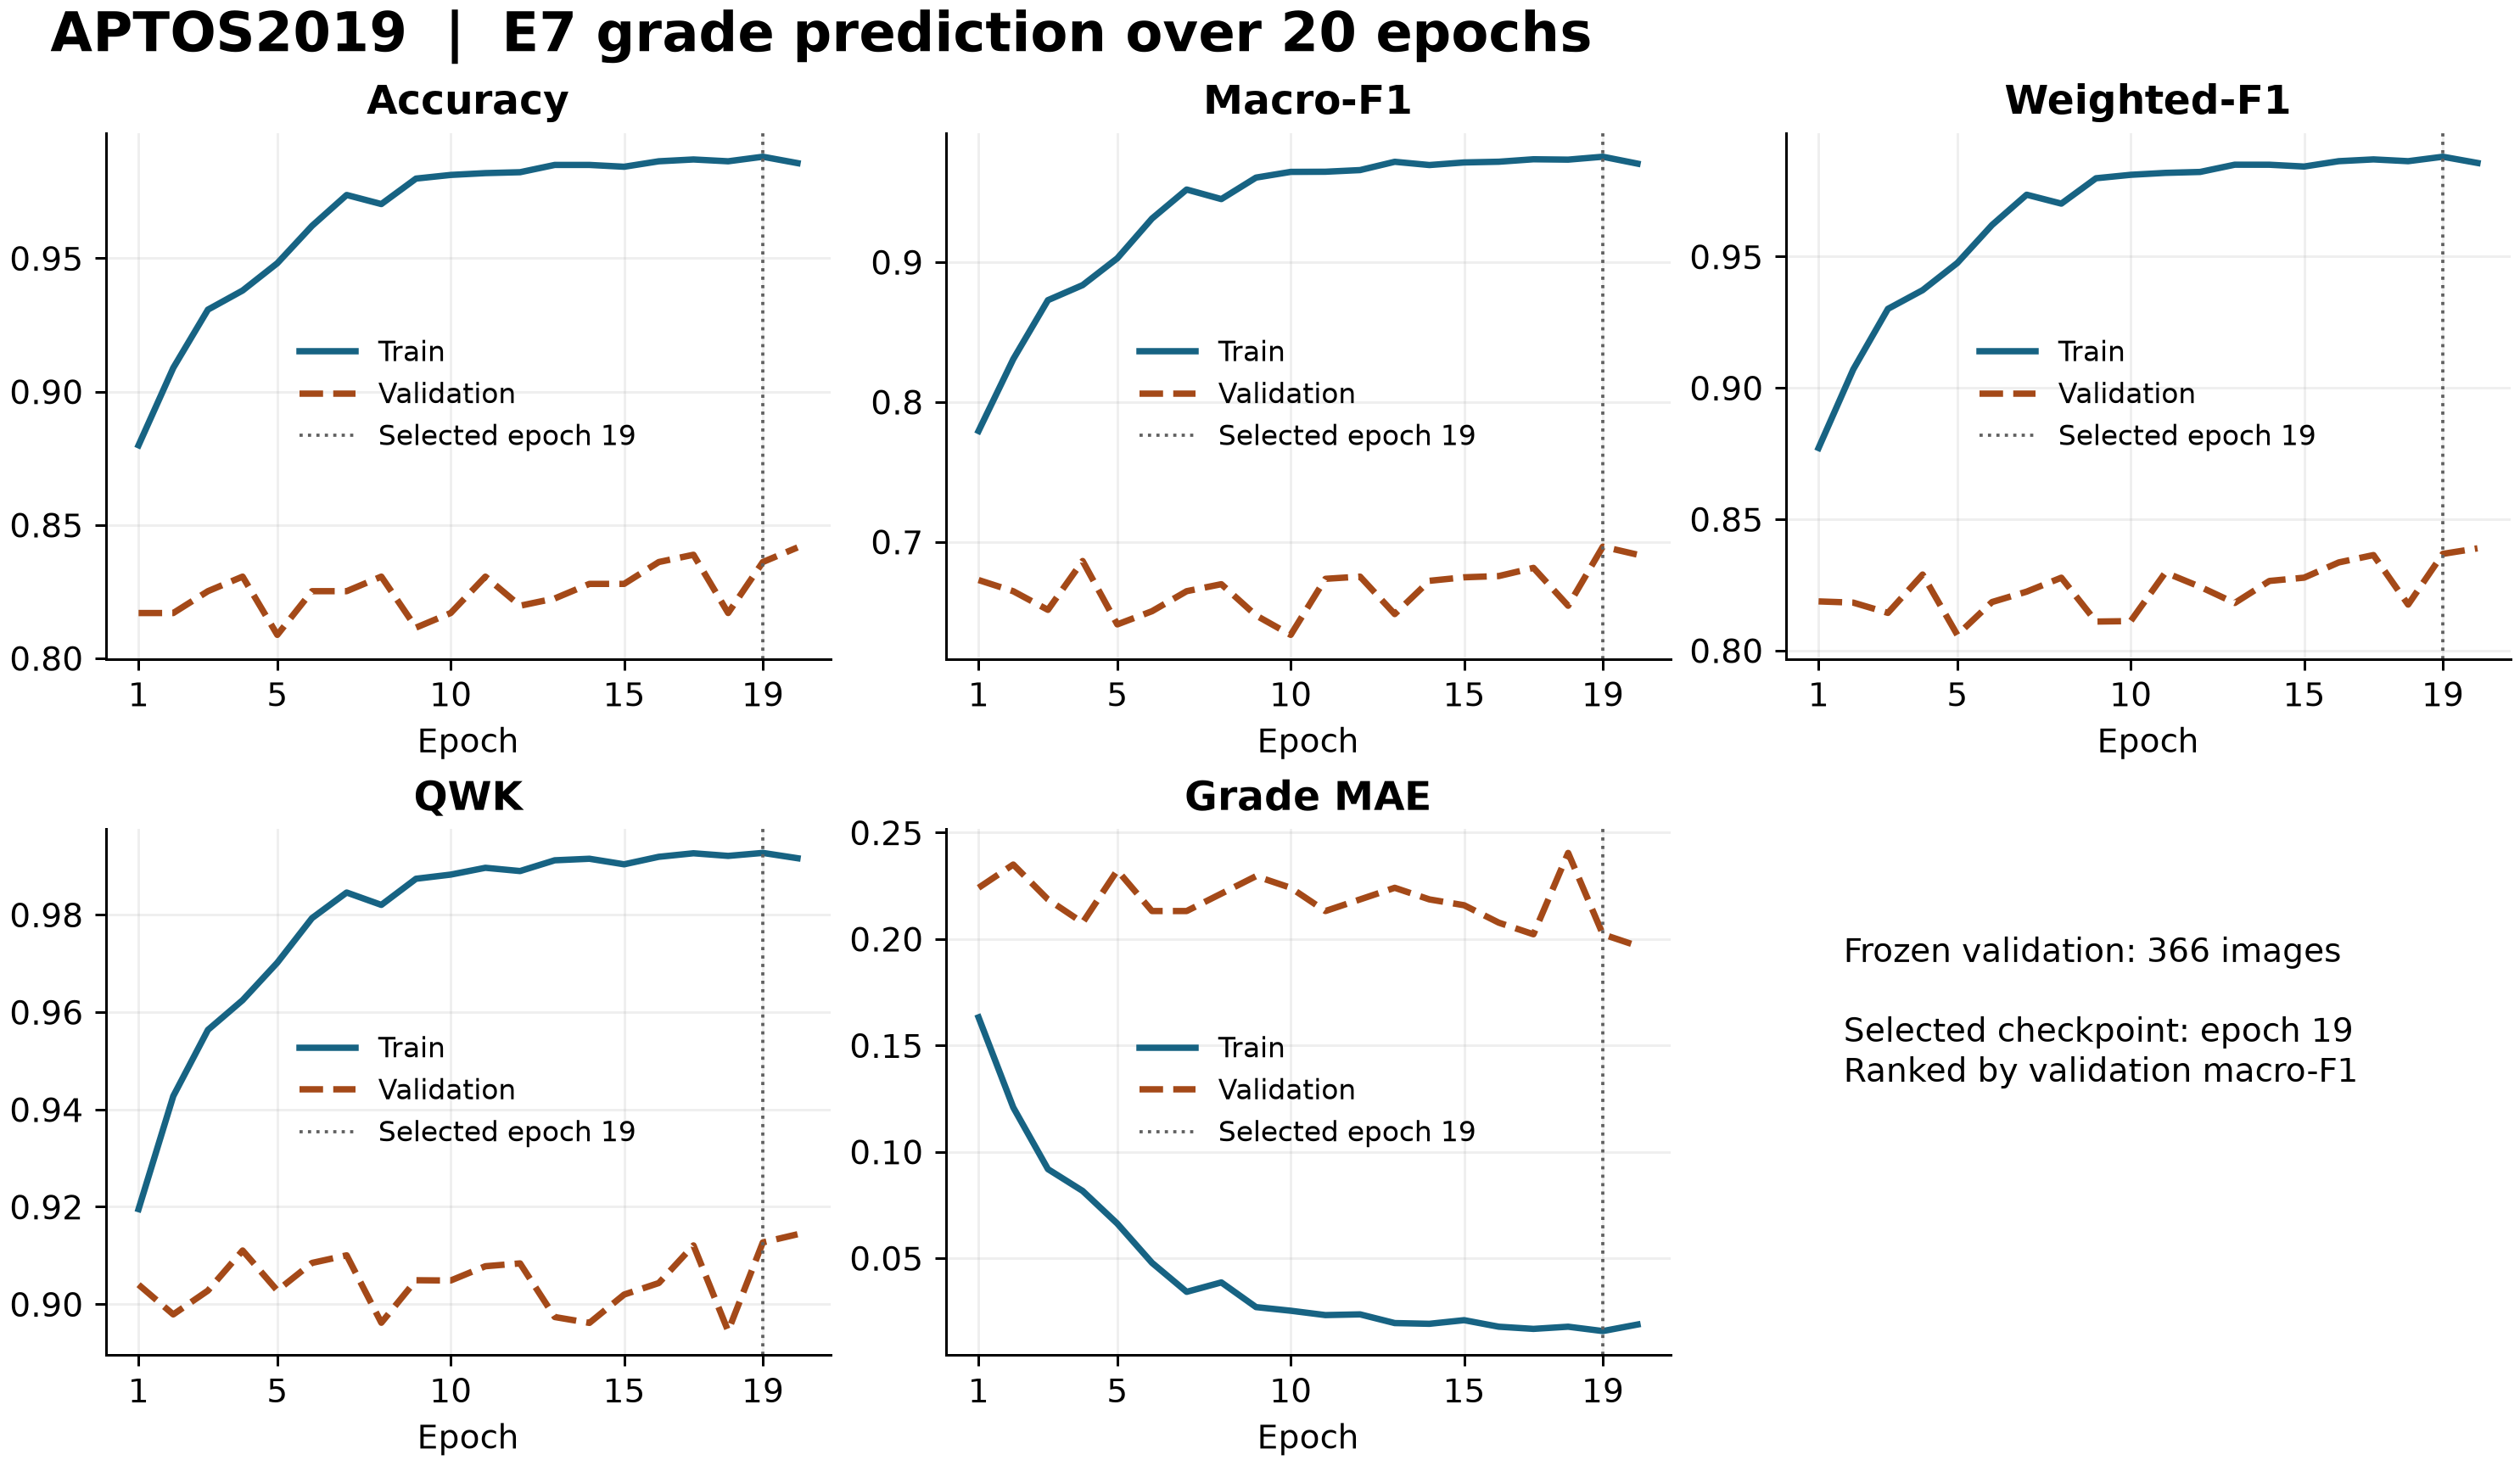

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/aptos2019_e7_epoch_scores.png')))

### Confusion at epoch 19

The left panel gives counts, and the right divides each row by true-grade support. Grade 1 recall was 24/35 and grade 3 recall was 8/20.

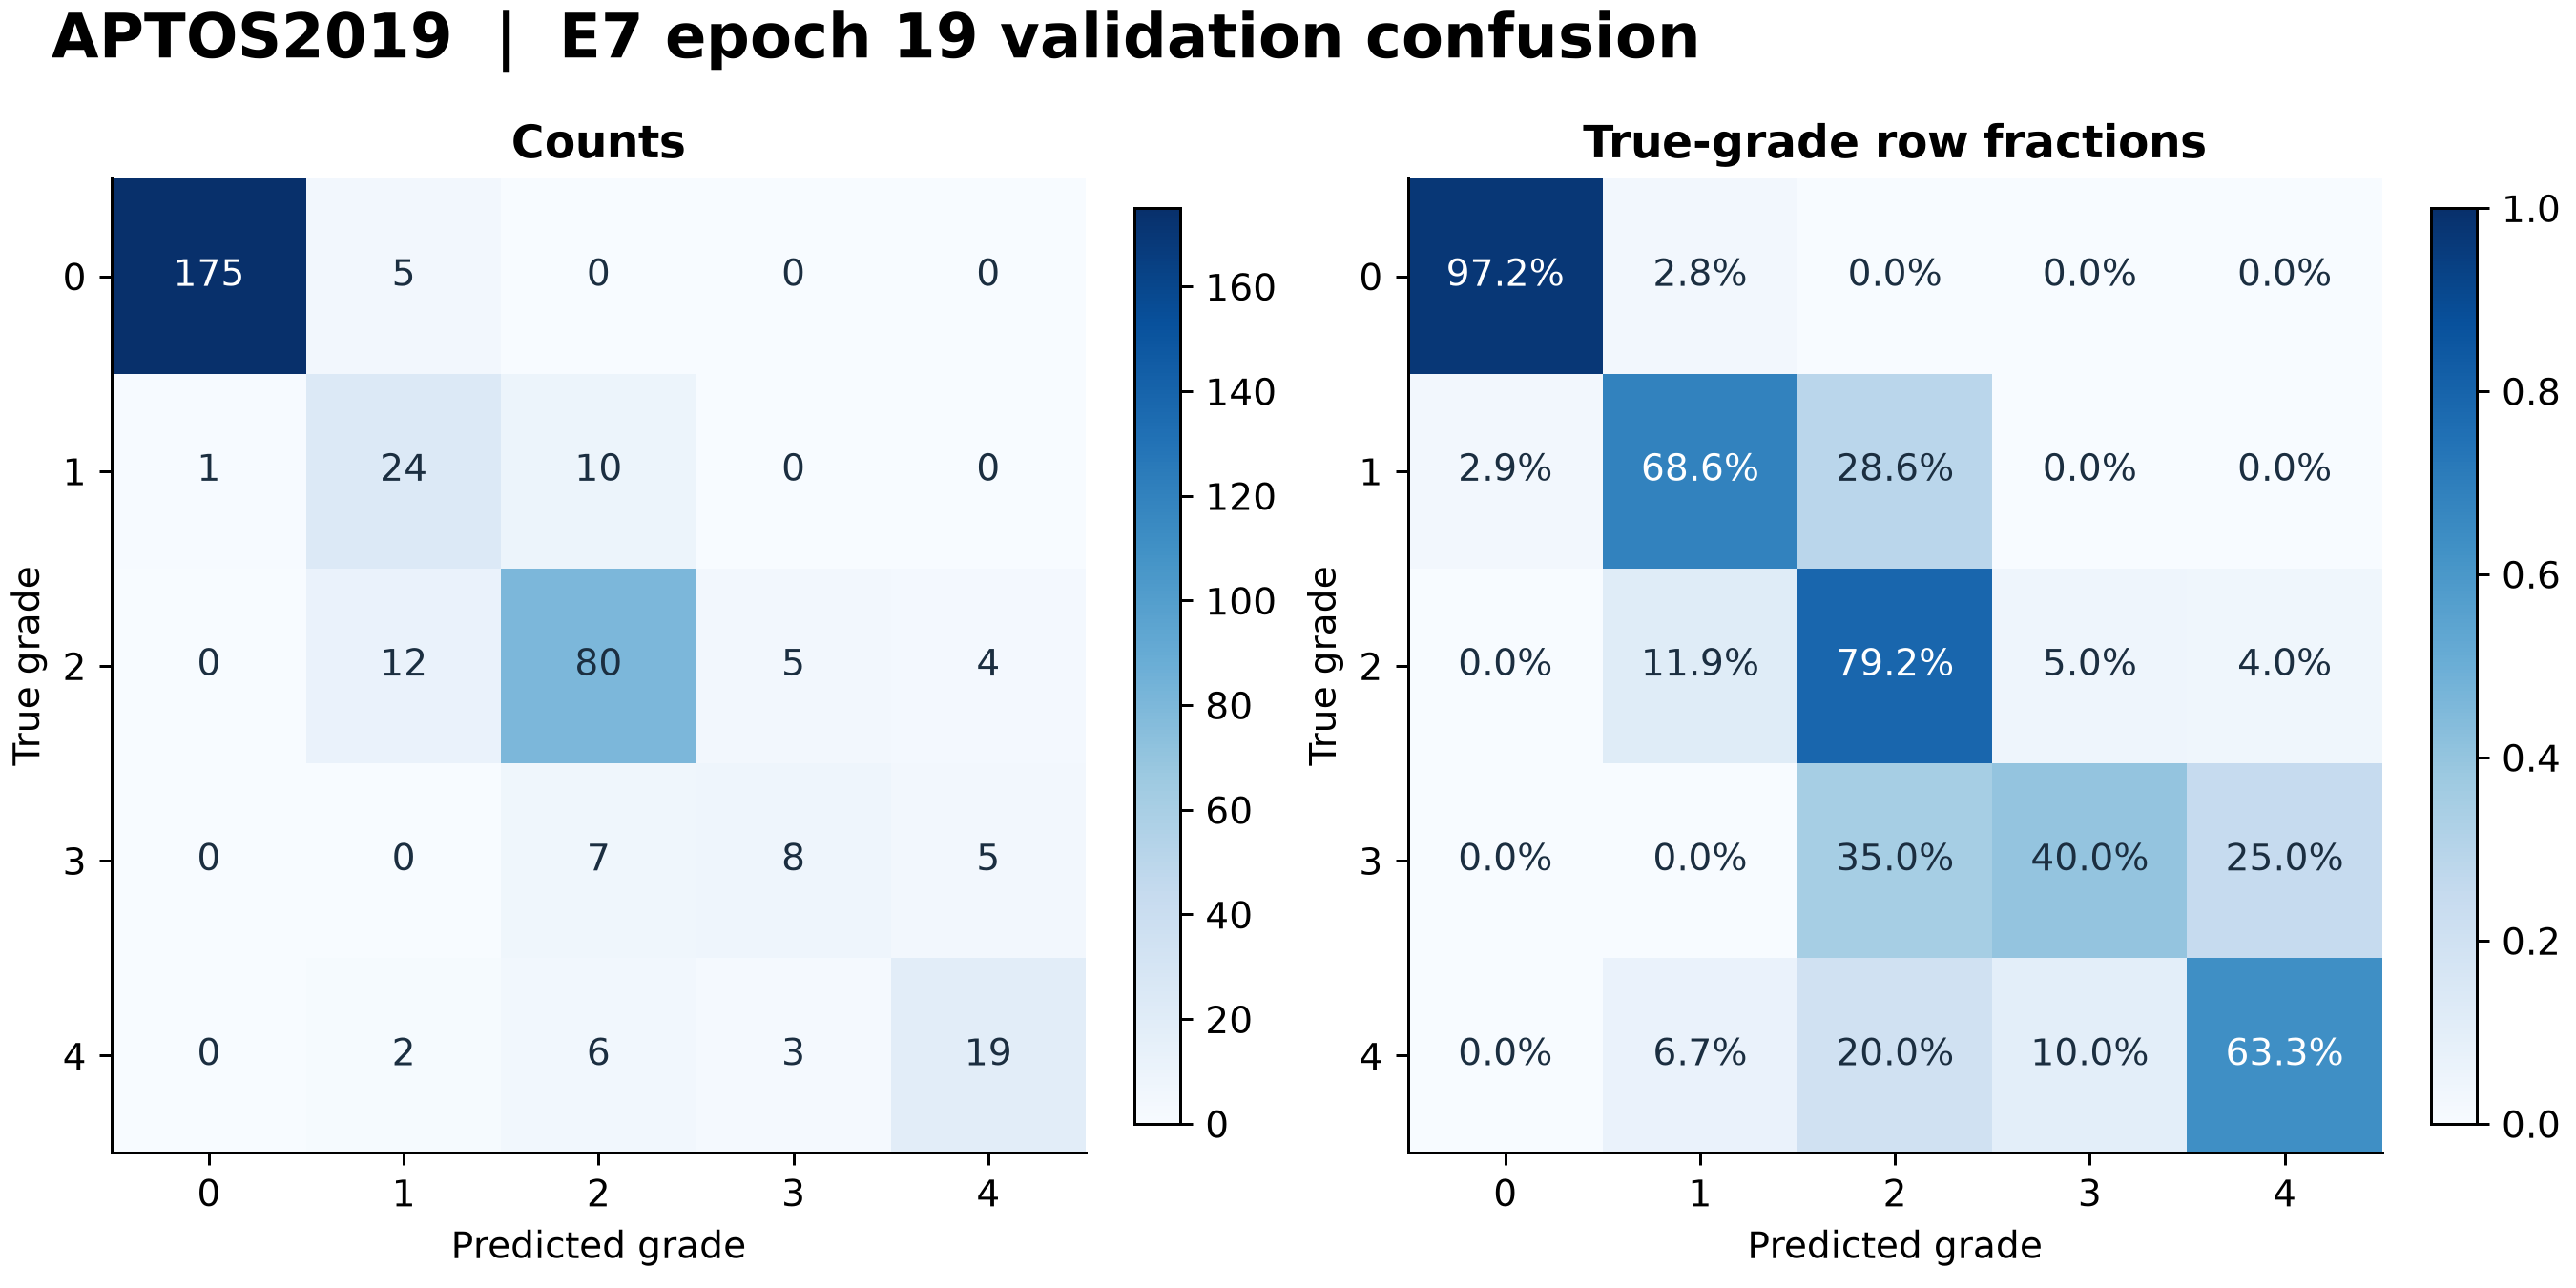

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/aptos2019_e7_confusion.png')))

### Selected E5, E6 and E7 validation checkpoints

| Selected validation metric | E5 | E6 | E7 |
| --- | --- | --- | --- |
| Best epoch | 16 | 15 | 19 |
| Macro-F1 | 0.705791432 | 0.679204179 | 0.696492253 |
| Accuracy | 0.830601093 | 0.789617486 | 0.836065574 |
| QWK | 0.899241254 | 0.880384339 | 0.912686517 |
| Grade MAE | 0.221311475 | 0.273224044 | 0.202185792 |
| Weighted-F1 | 0.833080466 | 0.795890536 | 0.836788255 |

The three checkpoints were selected on the same frozen validation split.

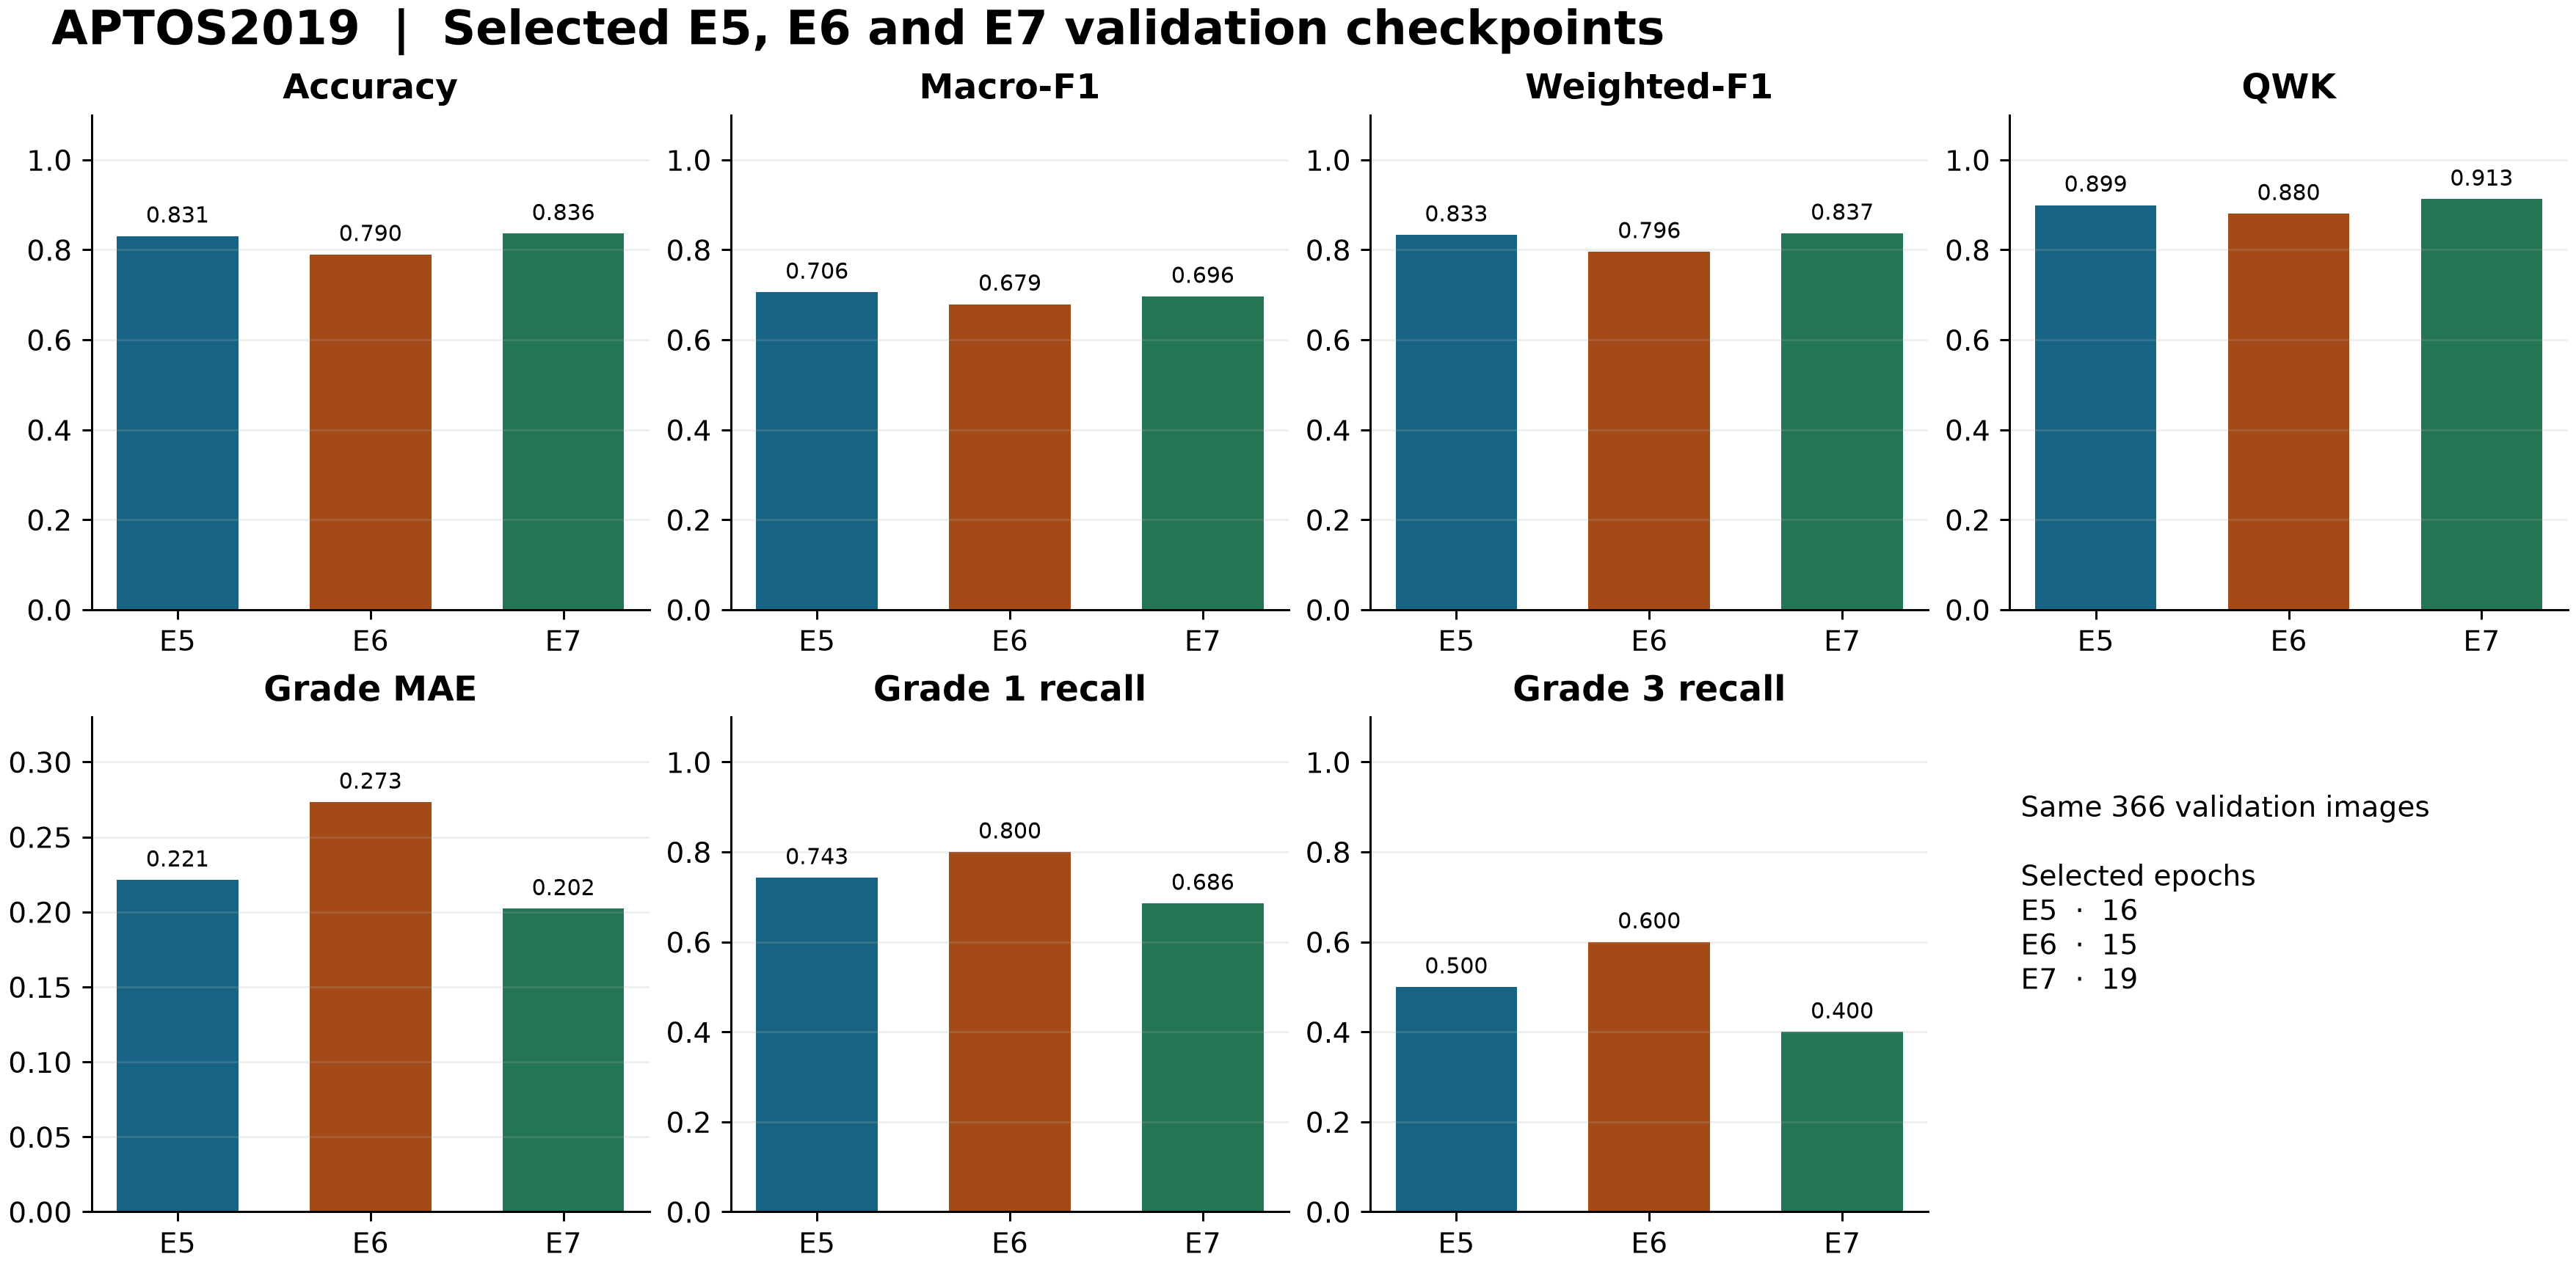

In [ ]:
from IPython.display import Image
display(Image(filename=str(ROOT / 'docs/figures/aptos2019_e7_e5_e6_e7_comparison.png')))

## Interpretation and limits

E7 had higher accuracy and QWK and lower grade MAE than E5, while E5 retained the highest macro-F1. E7 grade 1 and grade 3 recall were both lower than E5. These are single-seed, validation-selected observations. E7 warm-started from E5 and uses three views, so training budget and inference compute differ. This comparison provides no significance test or conclusion about clinical performance. No E7 final-test result is reported.

[Full validation report and figure index](../../results/APTOS2019/e7_global_local/validation_report.md).

## Optional execution of the authentic workflow

Set the external `DR_ARTIFACT_ROOT`, `DR_CONVNEXT_SNAPSHOT` and for writing steps `DR_NOTEBOOK_RUN_DIR`. Use the protocol's reviewed cache roots, size budgets and paths when applicable. `DR_MANIFEST_SOURCE_ROOT` supports moved roots for E5–E7. Authorize the local snapshot explicitly via `DR_TRUST_LEGACY_BIN=1` where required. GPU actions also require `DR_GPU_ALLOCATION_CONFIRMED=1`. For E7, use a fresh output directory below the external `foundation_e7` root. 

The [shared workflow bridge](../experiment_workflow.py) lists the exact environment keys and dispatches to the original CLI. Choose one step and enable its switch. Outputs must use a fresh external location. Report identity and cache validity remain enforced by the runner.

In [ ]:
from notebooks.experiment_workflow import run_step

ACTION = None
RUN_PREFLIGHT = False
RUN_CACHE = False
RUN_INPUT_VERIFICATION = False
RUN_GPU_SMOKE = False
RUN_BENCHMARK = False
RUN_TRAINING = False
RUN_CHECKPOINT_EXPORT = False
RUN_PRUNING = False
RUN_FINAL_TEST = False
if RUN_CHECKPOINT_EXPORT or RUN_PRUNING or RUN_FINAL_TEST:
    raise ValueError("Export, pruning and final-test inference are outside this workflow.")
run_step(ROOT, METHOD, DATASET, ACTION, CONFIG, {
    "preflight": RUN_PREFLIGHT, "estimate-cache": RUN_PREFLIGHT, "prepare-cache": RUN_CACHE,
    "verify-inputs": RUN_INPUT_VERIFICATION, "smoke": RUN_GPU_SMOKE,
    "benchmark": RUN_BENCHMARK, "train": RUN_TRAINING,
})